In [45]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split



from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

RANDOM_STATE = 42

## Step 1 – Load the data

In [32]:
mnist = pd.read_csv('G:/Python/AIML-TimesPro/Projects/Module 3/mnist_train.csv')
mnist.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [33]:
mnist.shape

(42000, 785)

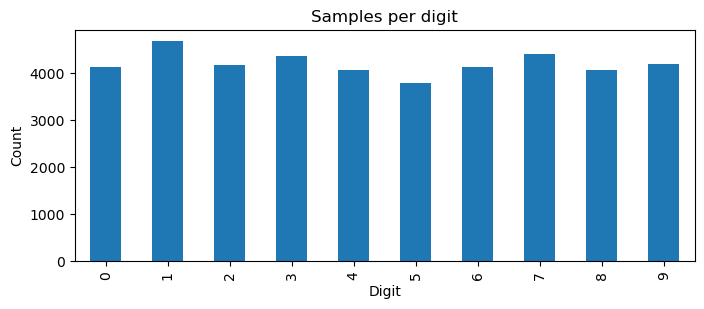

In [34]:
# Class balance – the ten digits are roughly equally represented
mnist['label'].value_counts().sort_index().plot(kind='bar', figsize=(8, 3),
                                                     title='Samples per digit')
plt.xlabel('Digit');
plt.ylabel('Count'); 
plt.show()

## Step 2 – Features, scaling and the 80:20 split

* `X` = the 784 pixel columns (vector representation of each image), `y` = `label`.
* Pixels are divided by 255 so every feature lies in [0, 1]. The distance- and gradient-based models (Logistic Regression, SVM, ANN) need this scaling. The tree-based models ignore it because splits depend only on the order of values.
* `stratify=y` keeps the same digit proportions in the train and test sets.

In [39]:
X_scaled = mnist.drop(columns=['label']).values.astype(np.float32) / 255.0
y = mnist['label'].values

train_X, test_X, train_y, test_y = train_test_split( X_scaled,
                                                  y,
                                                  test_size = 0.2,
                                                  stratify=y,
                                                  random_state = RANDOM_STATE )

In [40]:
print(f' Train X Shape : {train_X.shape},\n Test X Shape : {test_X.shape}\n')
print(f' Train Y Shape : {train_y.shape},\n Test y Shape : {test_y.shape}\n')

 Train X Shape : (33600, 784),
 Test X Shape : (8400, 784)

 Train Y Shape : (33600,),
 Test y Shape : (8400,)



## Step 3 – A common evaluation helper

For every model we record:
* **Train accuracy** and **Test accuracy**: the gap between them shows over-fitting.
* **Macro precision / recall / F1** on the test set.
* **Training time** and **prediction time** (in seconds) for the 8,400 test images.

In [59]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report,roc_auc_score)
results = {}
predictions = {}

def evaluate_model(name,model):
    t0 = time.time()
    model.fit(train_X, train_y)
    fit_time = time.time() - t0

    t0 = time.time()
    y_pred = model.predict(test_X)
    pred_time = time.time() - t0

    train_accuracy = accuracy_score(train_y,model.predict(train_X))
    test_accuracy = accuracy_score(test_y,model.predict(test_X))

    p, r, f1, _ = precision_recall_fscore_support(test_y, y_pred, average='macro')

    results[name] = ({'model': name, 'train_acc': train_accuracy, 'test_acc': test_accuracy,
                'precision': p, 'recall': r, 'f1': f1,
                'fit_time': fit_time, 'pred_time': pred_time})
    predictions[name] = y_pred
    print(f'{name}: train acc = {train_accuracy:.4f} | test acc = {test_accuracy:.4f} | '
          f'F1 = {f1:.4f} | fit = {fit_time:.1f}s | predict = {pred_time:.2f}s')
    return model

## Step 4 – Train and evaluate each model

### 4.1 Logistic Regression
Multinomial (softmax) logistic regression: one linear decision boundary per class, with L2 regularisation.

In [60]:
from sklearn.linear_model import LogisticRegression

logreg = evaluate_model('Logistic Regression',
                  LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

Logistic Regression: train acc = 0.9456 | test acc = 0.9136 | F1 = 0.9124 | fit = 6.0s | predict = 0.02s


In [69]:
proba = logreg.predict_proba(test_X)

logreg_pred = pd.DataFrame(proba, columns=[f'prob_{c}' for c in logreg.classes_])
logreg_pred.insert(0, 'actual', test_y)
logreg_pred['predicted'] = logreg.classes_[proba.argmax(axis=1)]
logreg_pred['confidence'] = proba.max(axis=1)

prob_cols = [c for c in logreg_pred.columns if c.startswith('prob_')] + ['confidence']
logreg_pred[prob_cols] = logreg_pred[prob_cols].round(3)
logreg_pred.head()

,actual,prob_0,prob_1,prob_2,prob_3,prob_4,prob_5,prob_6,prob_7,prob_8,prob_9,predicted,confidence
0,1,0.0,1.000,0.000,0.000,0.0,0.000,0.0,0.000,0.000,0.000,1,1.000
1,8,0.0,0.000,0.000,0.010,0.0,0.002,0.0,0.000,0.986,0.001,8,0.986
2,6,0.0,0.000,0.000,0.000,0.0,0.000,1.0,0.000,0.000,0.000,6,1.000
3,9,0.0,0.186,0.010,0.104,0.0,0.000,0.0,0.084,0.562,0.054,8,0.562
4,5,0.0,0.008,0.001,0.000,0.0,0.980,0.0,0.000,0.011,0.000,5,0.980


### 4.2 Decision Tree
A single CART tree that uses Gini impurity. It is grown without a depth limit, so it shows the typical behaviour of a lone tree.

In [73]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

from sklearn.model_selection import train_test_split
X_tune, _, y_tune, _ = train_test_split(train_X, train_y, train_size=5000,
                                        stratify=train_y, random_state=RANDOM_STATE)
param_grid = {'max_depth': np.arange(3, 15), 'max_leaf_nodes': np.arange(5,11)}
tree = GridSearchCV(DecisionTreeClassifier(), param_grid, cv = 10, scoring='accuracy',n_jobs=-1,verbose=True)
tree.fit(X_tune, y_tune )

Fitting 10 folds for each of 72 candidates, totalling 720 fits


,estimator,DecisionTreeClassifier()
,param_grid,"{'max_depth': array([ 3, 4..., 12, 13, 14]), 'max_leaf_nodes': array([ 5, 6..., 8, 9, 10])}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,10
,verbose,True
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [75]:
tree.best_params_

{'max_depth': np.int64(5), 'max_leaf_nodes': np.int64(10)}

In [81]:
# dtree = evaluate_model('Decision Tree', DecisionTreeClassifier(max_depth=5,max_leaf_nodes=10,
#                                                         random_state=RANDOM_STATE))
dtree = evaluate_model('Decision Tree', DecisionTreeClassifier(random_state=RANDOM_STATE))

Decision Tree: train acc = 1.0000 | test acc = 0.8554 | F1 = 0.8537 | fit = 7.0s | predict = 0.00s


In [82]:
print('Tree depth:', dtree.get_depth(), '| leaves:', dtree.get_n_leaves())

Tree depth: 44 | leaves: 2559


### 4.3 Bagging

In [ ]:
import sklearn.ensemble as en
from sklearn.ensemble import BaggingClassifier

bagclm = evaluate_model('Bagging Classifier',
                         BaggingClassifier(oob_score=True, n_estimators=50,
                                            verbose=True,n_jobs=-1,random_state=RANDOM_STATE))

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 out of   8 | elapsed:  1.3min remaining:  3.9min
[Parallel(n_jobs=8)]: Done   8 out of   8 | elapsed:  1.4min finished
[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 out of   8 | elapsed:    0.4s remaining:    1.5s
[Parallel(n_jobs=8)]: Done   8 out of   8 | elapsed:    0.5s finished
[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 out of   8 | elapsed:    2.2s remaining:    6.7s
[Parallel(n_jobs=8)]: Done   8 out of   8 | elapsed:    2.4s finished
[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.


Bagging Classifier: train acc = 0.9999 | test acc = 0.9463 | F1 = 0.9456 | fit = 89.5s | predict = 0.84s


[Parallel(n_jobs=8)]: Done   2 out of   8 | elapsed:    0.4s remaining:    1.5s
[Parallel(n_jobs=8)]: Done   8 out of   8 | elapsed:    0.5s finished


### 4.4 Random Forest
Bagging of 200 de-correlated trees, where each split considers √784 ≈ 28 random pixels.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

radm_clf = evaluate_model('RandomForest Classifier',
                          RandomForestClassifier(oob_score=True,
                                                 n_jobs=-1,
                                                 verbose=True,
                                                 random_state=RANDOM_STATE,   
                                                 n_estimators=100 ))

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    1.0s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    2.8s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.


RandomForest Classifier: train acc = 1.0000 | test acc = 0.9639 | F1 = 0.9635 | fit = 4.5s | predict = 0.10s


[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 100 out of 100 | elapsed:    0.1s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.0s
[Parallel(n_jobs=8)]: Done 100 out of 100 | elapsed:    0.0s finished


### 4.4 Gradient Boosting
Trees are added one after another, and each new tree fits the gradient of the loss left by the current ensemble.

*Implementation note:* the classic `GradientBoostingClassifier` builds 10 trees (one per class) per round over all 784 exact feature values, which takes far too long on 33,600 samples. `HistGradientBoostingClassifier` is scikit-learn's histogram-based implementation of **the same gradient boosting algorithm**. It bins each feature into 255 buckets, which makes it much faster, and it is the approach LightGBM popularised.

In [92]:
from sklearn.ensemble import HistGradientBoostingClassifier

gscv_hgb = evaluate_model('HistGradientBoosting',
                     HistGradientBoostingClassifier(learning_rate=0.1, max_iter=200,
                                                    early_stopping=True,
                                                    verbose=True,    
                                                    random_state=RANDOM_STATE))


Binning 0.190 GB of training data: 1.124 s
Binning 0.021 GB of validation data: 0.033 s
Fitting gradient boosted rounds:
Fit 1160 trees in 97.821 s, (35960 total leaves)
Time spent computing histograms: 69.290s
Time spent finding best splits:  13.041s
Time spent applying splits:      2.642s
Time spent predicting:           0.163s
HistGradientBoosting: train acc = 0.9975 | test acc = 0.9743 | F1 = 0.9740 | fit = 97.9s | predict = 1.06s


### 4.5 XGBoost
Extreme Gradient Boosting adds a second-order (Newton) approximation of the loss, L1/L2 regularisation on leaf weights, row and column subsampling, and multi-threaded histogram tree building.

In [94]:
import xgboost as xgb
from xgboost import XGBClassifier

xgb = evaluate_model('XGBoost',
               XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                             subsample=0.8, colsample_bytree=0.5,
                             tree_method='hist', n_jobs=-1, random_state=RANDOM_STATE))

XGBoost: train acc = 1.0000 | test acc = 0.9752 | F1 = 0.9750 | fit = 146.4s | predict = 0.09s


### 4.6 Support Vector Machine
An SVM with an RBF (Gaussian) kernel. The kernel trick lets the SVM find a maximum-margin boundary in a high-dimensional feature space without computing that space explicitly. Multiclass is handled one-vs-one (45 binary SVMs).

In [97]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

svm_rbf = evaluate_model('SVM (RBF)', SVC(kernel='rbf', 
                                          C=10, 
                                          gamma='scale', 
                                          random_state=RANDOM_STATE))
print('Support vectors:', svm_rbf.n_support_.sum(), 'of', len(train_X), 'training samples')

SVM (RBF): train acc = 0.9999 | test acc = 0.9792 | F1 = 0.9789 | fit = 100.4s | predict = 48.03s
Support vectors: 8035 of 33600 training samples


In [99]:
from sklearn.svm import SVC

svm_poly = evaluate_model('SVM (Poly)', SVC(kernel='poly', 
                                            C=10, 
                                            gamma='scale', 
                                            random_state=RANDOM_STATE))
print('Support vectors:', svm_poly.n_support_.sum(), 'of', len(train_X), 'training samples')

SVM (Poly): train acc = 0.9998 | test acc = 0.9742 | F1 = 0.9739 | fit = 79.1s | predict = 18.25s
Support vectors: 5369 of 33600 training samples


### 4.7 Artificial Neural Network
A fully-connected Multi-Layer Perceptron: 784 → 256 → 128 → 10, with ReLU activations, the Adam optimiser, L2 penalty (`alpha`), and early stopping on a 10% validation split.

In [100]:
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(RANDOM_STATE)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# train_X/test_X are already scaled to 0-1 float32
X_train_t = torch.tensor(train_X, dtype=torch.float32)
X_test_t  = torch.tensor(test_X,  dtype=torch.float32)
y_train_t = torch.tensor(train_y, dtype=torch.long)   # CrossEntropyLoss needs int64 labels
y_test_t  = torch.tensor(test_y,  dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=128, shuffle=True)


#### Network architecture: flow from input to output

Each hidden layer runs four steps in order: **Linear → ReLU → BatchNorm → Dropout**.
- **Aggregate (summation) function:** Linear layer, a weighted sum plus bias, $z = Wx + b$
- **Activation function:** ReLU, $a = \max(0, z)$
- **BatchNorm** and **Dropout** are normalisation/regularisation steps, not activations.

**Input layer**: 784 features (28×28 image flattened)
<div align="center">⬇</div>

**Hidden layer 1 (256 neurons)**
1. Aggregate: Linear(784 → 256), $z_1 = W_1 x + b_1$
2. Activation: ReLU, $a_1 = \max(0, z_1)$
3. BatchNorm(256): normalises each neuron over the batch
4. Dropout(0.3): zeroes 30% of outputs (training only)
<div align="center">⬇</div>

**Hidden layer 2 (128 neurons)**
1. Aggregate: Linear(256 → 128), $z_2 = W_2 a_1 + b_2$
2. Activation: ReLU, $a_2 = \max(0, z_2)$
3. BatchNorm(128)
4. Dropout(0.3)
<div align="center">⬇</div>

**Output layer (10 neurons, one per digit 0–9)**
1. Aggregate: Linear(128 → 10), $z_3 = W_3 a_2 + b_3$
2. Activation: none inside the model, so it outputs raw scores (logits)
<div align="center">⬇</div>

**Output activation (applied outside the model)**
- Training: CrossEntropyLoss applies log-softmax internally
- Prediction: softmax turns the 10 logits into probabilities that sum to 1

| Layer | Neurons | Aggregate function | Activation | Extras | Trainable params |
|---|---|---|---|---|---|
| Input | 784 | none | none | none | 0 |
| Hidden 1 | 256 | $Wx + b$ | ReLU | BatchNorm, Dropout(0.3) | 200,960 + 512 (BN) |
| Hidden 2 | 128 | $Wx + b$ | ReLU | BatchNorm, Dropout(0.3) | 32,896 + 256 (BN) |
| Output | 10 | $Wx + b$ | Softmax (in the loss / at prediction) | none | 1,290 |
| **Total** | | | | | **235,914** |

> BatchNorm and Dropout behave differently in training and evaluation mode: in eval mode Dropout is off and BatchNorm uses its running statistics.

In [103]:
class MNISTModel(nn.Module):

    def __init__(self, n_in, out_sz, layers, p=0.3):
        super().__init__()

        layerlist = []
        for i in layers:
            layerlist.append(nn.Linear(n_in, i))
            layerlist.append(nn.ReLU(inplace=True))
            layerlist.append(nn.BatchNorm1d(i))
            layerlist.append(nn.Dropout(p))
            n_in = i
        layerlist.append(nn.Linear(n_in, out_sz))

        self.layers = nn.Sequential(*layerlist)

    def forward(self, x):
        return self.layers(x)         

model = MNISTModel(n_in=784, out_sz=10, layers=[256, 128], p=0.3).to(device)
model


MNISTModel(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU(inplace=True)
    (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU(inplace=True)
    (6): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=10, bias=True)
  )
)

Epoch  1/25  loss: 0.3495
Epoch  2/25  loss: 0.1599
Epoch  3/25  loss: 0.1246
Epoch  4/25  loss: 0.1037
Epoch  5/25  loss: 0.0917
Epoch  6/25  loss: 0.0826
Epoch  7/25  loss: 0.0731
Epoch  8/25  loss: 0.0634
Epoch  9/25  loss: 0.0626
Epoch 10/25  loss: 0.0564
Epoch 11/25  loss: 0.0532
Epoch 12/25  loss: 0.0486
Epoch 13/25  loss: 0.0474
Epoch 14/25  loss: 0.0443
Epoch 15/25  loss: 0.0429
Epoch 16/25  loss: 0.0417
Epoch 17/25  loss: 0.0395
Epoch 18/25  loss: 0.0376
Epoch 19/25  loss: 0.0344
Epoch 20/25  loss: 0.0337
Epoch 21/25  loss: 0.0355
Epoch 22/25  loss: 0.0329
Epoch 23/25  loss: 0.0320
Epoch 24/25  loss: 0.0294
Epoch 25/25  loss: 0.0333


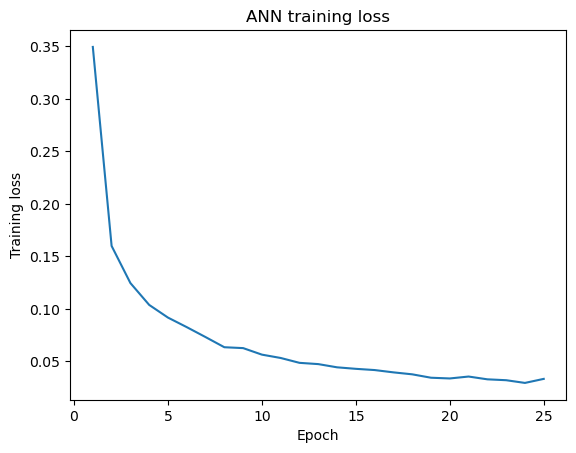

In [104]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 25
train_losses = []

t0 = time.time()
for epoch in range(epochs):
    model.train()                      # enables dropout + batchnorm updates
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        y_logits = model(X_batch)
        loss = criterion(y_logits, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(X_batch)

    epoch_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_loss)
    print(f'Epoch {epoch+1:2d}/{epochs}  loss: {epoch_loss:.4f}')
fit_time = time.time() - t0

plt.plot(range(1, epochs+1), train_losses)
plt.xlabel('Epoch'); plt.ylabel('Training loss'); plt.title('ANN training loss')
plt.show()


In [107]:
def ann_predict_proba(X_t):
    model.eval()                       # disables dropout, uses running batchnorm stats
    with torch.no_grad():
        return torch.softmax(model(X_t.to(device)), dim=1).cpu().numpy()

t0 = time.time()
test_proba = ann_predict_proba(X_test_t)
pred_time = time.time() - t0
train_proba = ann_predict_proba(X_train_t)

y_pred = test_proba.argmax(axis=1)
train_accuracy = accuracy_score(train_y, train_proba.argmax(axis=1))
test_accuracy  = accuracy_score(test_y, y_pred)
p, r, f1, _ = precision_recall_fscore_support(test_y, y_pred, average='macro')

name = 'ANN (PyTorch)'
results[name] = ({'model': name, 'train_acc': train_accuracy, 'test_acc': test_accuracy,
                'precision': p, 'recall': r, 'f1': f1,
                'fit_time': fit_time, 'pred_time': pred_time})
predictions[name] = y_pred
print(f'{name}: train acc = {train_accuracy:.4f} | test acc = {test_accuracy:.4f} | '
      f'F1 = {f1:.4f} | fit = {fit_time:.1f}s | predict = {pred_time:.2f}s')


ANN (PyTorch): train acc = 0.9988 | test acc = 0.9780 | F1 = 0.9777 | fit = 52.2s | predict = 0.07s


## Step 5 – Comparison of all methods

In [ ]:
results_df = (pd.DataFrame.from_dict(results, orient='index')
                .drop(columns='model')
                .sort_values('test_acc', ascending=False))
results_df['Overfit gap'] = results_df['train_acc'] - results_df['test_acc']
results_df.style.format({c: '{:.4f}' for c in ['train_acc', 'test_acc', 'precision', 'recall', 'f1', 'Overfit gap']}
                        | {'fit_time': '{:.1f}', 'predict_time': '{:.2f}'}) \
          .background_gradient(subset=['test_acc'], cmap='Greens')

,train_acc,test_acc,precision,recall,f1,fit_time,pred_time,Overfit gap
SVM (RBF),0.9999,0.9792,0.9789,0.9789,0.9789,100.4,48.034780,0.0207
ANN (PyTorch),0.9988,0.9780,0.9778,0.9776,0.9777,52.2,0.067853,0.0208
XGBoost,1.0000,0.9752,0.9751,0.9750,0.9750,146.4,0.088425,0.0248
HistGradientBoosting,0.9975,0.9743,0.9741,0.9740,0.9740,97.9,1.064766,0.0232
SVM (Poly),0.9998,0.9742,0.9739,0.9738,0.9739,79.1,18.250155,0.0257
RandomForest Classifier,1.0000,0.9639,0.9635,0.9636,0.9635,4.5,0.100132,0.0361
Bagging Classifier,0.9999,0.9463,0.9457,0.9457,0.9456,89.5,0.835534,0.0536
Logistic Regression,0.9456,0.9136,0.9127,0.9123,0.9124,6.0,0.018828,0.0320
Decision Tree,1.0000,0.8554,0.8537,0.8537,0.8537,7.0,0.004704,0.1446


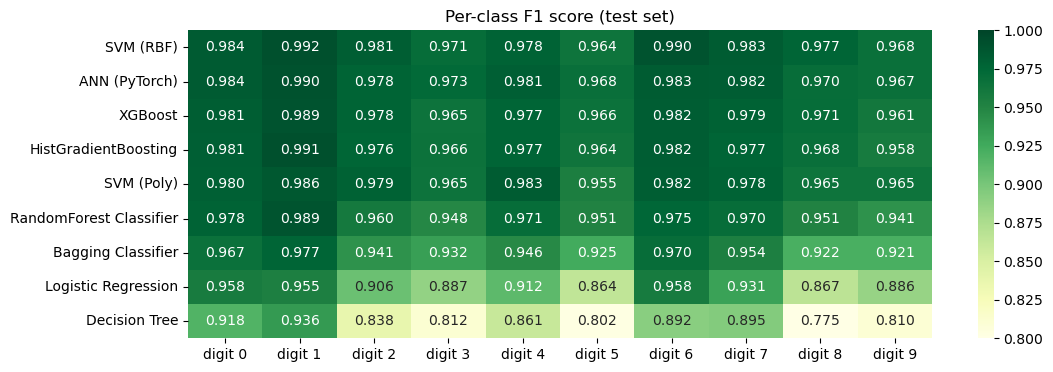

In [129]:
import seaborn as sns
order = results_df.index.tolist()          

per_class_f1 = pd.DataFrame({name: precision_recall_fscore_support(test_y, predictions[name])[2]
                             for name in order}, index=[f'digit {d}' for d in range(10)]).T
plt.figure(figsize=(12, 4))
sns.heatmap(per_class_f1, annot=True, fmt='.3f', cmap='YlGn', vmin=0.8, vmax=1.0)
plt.title('Per-class F1 score (test set)'); plt.show()

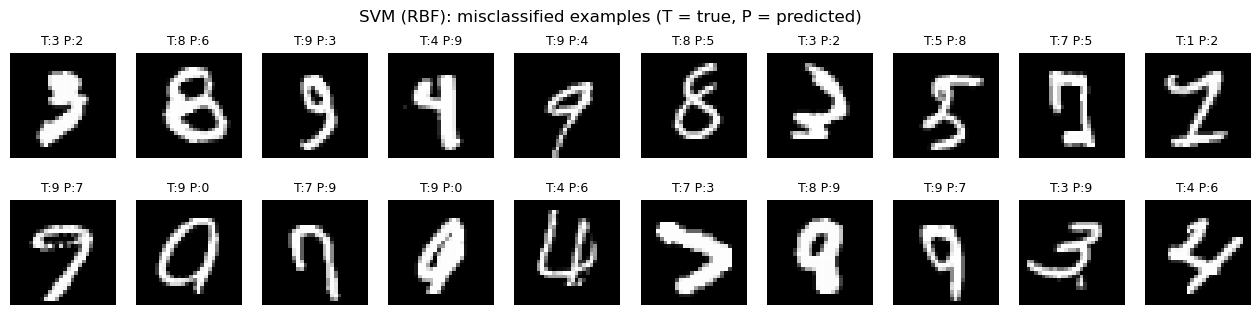

In [130]:
# Misclassified test images from the best model
best = results_df.index[0]
wrong = np.where(predictions[best] != test_y)[0][:20]
plt.figure(figsize=(16, 3.5))
for i, idx in enumerate(wrong):
    plt.subplot(2, 10, i + 1)
    plt.imshow(test_X[idx].reshape(28, 28), cmap='gray')
    plt.title(f'T:{test_y[idx]} P:{predictions[best][idx]}', fontsize=9); plt.axis('off')
plt.suptitle(f'{best}: misclassified examples (T = true, P = predicted)'); plt.show()